<a href="https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X2b_vetores2d_sistemas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# Domínio II (b): sistemas de equações no plano

## Retas que se cruzam, círculos que se cruzam e a mira de um projétil

**Série:** [raiz](X0_raiz.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X0_raiz.ipynb)) · **Domínio:** [nó 2](X2_vetores2d.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X2_vetores2d.ipynb)) · **Anterior:** [X2a_vetores2d_algebra.ipynb](X2a_vetores2d_algebra.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X2a_vetores2d_algebra.ipynb)) · **Próximo:** [X2c_vetores2d_edo.ipynb](X2c_vetores2d_edo.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X2c_vetores2d_edo.ipynb))

**Objetivo.** Resolver sistemas de duas incógnitas, as coordenadas de um ponto do plano, e ver a **geometria** por trás de cada sistema:
- um sistema linear $2\times2$ é o cruzamento de **duas retas**; o condicionamento é o ângulo entre elas;
- localizar um ponto por **distâncias** a pontos conhecidos é cruzar **círculos**: um sistema não linear, com duas soluções quando há só dois círculos, que vira linear por um truque e vira mínimos quadrados quando há mais medidas que incógnitas;
- **mirar** um projétil com arrasto é um sistema não linear em (ângulo, tempo) com duas soluções físicas (o tiro direto e o tiro por cima), e o Newton escolhe uma delas conforme o ponto de partida.

Os três problemas reaparecem na etapa (d): Pepé localiza Penélope por direção (retas) e por distância (círculos), e as ambiguidades desta etapa são as ambiguidades do filtro de lá.

**Roteiro**
1. Duas retas: interseção e condicionamento
2. Dois círculos: a trilateração, suas duas soluções e o truque que a torna linear
3. Mais medidas que incógnitas: mínimos quadrados, Gauss–Newton e a geometria das balizas
4. Mirar um projétil com arrasto: Newton em duas variáveis e as bacias de atração
5. Exercícios

In [1]:
# Ferramentas comuns da série (repetidas em todos os notebooks, para que cada um rode sozinho no Colab)
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 100,
                     "axes.spines.top": False, "axes.spines.right": False})

def confere(nome, obtido, esperado, tol=1e-9, relativo=False):
    """Compara duas quantidades. Imprime OK ou interrompe o notebook com uma mensagem clara."""
    a, b = np.asarray(obtido, dtype=float), np.asarray(esperado, dtype=float)
    escala = max(np.max(np.abs(b)), 1e-300) if relativo else 1.0
    erro = float(np.max(np.abs(a - b)) / escala)
    ok = erro <= tol
    print(f"{'OK ' if ok else 'FALHOU'}  {nome}:  diferença {'relativa ' if relativo else ''}máxima = {erro:.2e}")
    assert ok, f"conferência falhou: {nome}"

import sympy as sp
from scipy import optimize
rng = np.random.default_rng(22)

---

## 1. Duas retas: interseção e condicionamento

Dois observadores, em $O_1$ e $O_2$, veem Penélope nas direções $\theta_1$ e $\theta_2$. Cada observação diz que ela está numa **reta**: a reta que passa por $O_i$ com direção $(\cos\theta_i,\sin\theta_i)$. Um ponto $p$ está nessa reta quando o vetor $p-O_i$ não tem componente na direção perpendicular $\mathbf n_i=(-\sin\theta_i,\cos\theta_i)$:

$$\mathbf n_i\cdot(p-O_i)=0\quad\Longleftrightarrow\quad -\sin\theta_i\,x+\cos\theta_i\,y=\mathbf n_i\cdot O_i .$$

Duas observações dão um sistema linear $2\times2$, $\mathbf A p=\mathbf b$, com as normais nas linhas de $\mathbf A$. É a **triangulação**, o método dos agrimensores e dos navegadores.

**O condicionamento é o ângulo.** Se as duas direções são quase iguais, as retas são quase paralelas e o cruzamento fica muito sensível: um erro pequeno no ângulo medido desloca o cruzamento para muito longe. Para duas retas que se cruzam com ângulo $\gamma$, o número de condição de $\mathbf A$ é $\kappa=\cot(\gamma/2)\approx2/\gamma$ para $\gamma$ pequeno.

In [2]:
def reta(O, th):
    """Uma linha do sistema: n·p = n·O, com n perpendicular à direção observada."""
    n = np.array([-np.sin(th), np.cos(th)])
    return n, n @ O

def triangula(O1, th1, O2, th2):
    (n1, b1), (n2, b2) = reta(O1, th1), reta(O2, th2)
    return np.linalg.solve(np.array([n1, n2]), np.array([b1, b2]))

alvo = np.array([20.0, 30.0])
O1 = np.array([0.0, 0.0])
sig_th = np.deg2rad(1.0)                       # cada observador erra a direção em 1° (desvio)
print(" ângulo entre as retas    κ(A)   cot(γ/2)   erro mediano do cruzamento (m, 2000 sorteios)")
linhas_tab = []
for O2 in [np.array([40.0, 0.0]), np.array([10.0, 0.0]), np.array([2.0, 0.0]), np.array([0.5, 0.0])]:
    th1 = np.arctan2(*(alvo - O1)[::-1]); th2 = np.arctan2(*(alvo - O2)[::-1])
    gam = abs(th2 - th1)
    A = np.array([reta(O1, th1)[0], reta(O2, th2)[0]])
    confere(f"  sem ruído, o cruzamento é o alvo (O2 = {O2[0]:g} m)", triangula(O1, th1, O2, th2), alvo, tol=1e-10)
    E = np.array([triangula(O1, th1 + sig_th * rng.standard_normal(), O2, th2 + sig_th * rng.standard_normal()) - alvo
                  for _ in range(2000)])
    linhas_tab.append((np.degrees(gam), np.linalg.cond(A), 1 / np.tan(gam / 2), np.median(np.hypot(*E.T))))
for g_, k_, cot_, e_ in linhas_tab:
    print(f"{g_:18.2f}°  {k_:8.1f}  {cot_:8.1f}   {e_:8.2f}")
confere("κ(A) = cot(γ/2)", [l[1] for l in linhas_tab], [l[2] for l in linhas_tab], tol=1e-9, relativo=True)

 ângulo entre as retas    κ(A)   cot(γ/2)   erro mediano do cruzamento (m, 2000 sorteios)
OK     sem ruído, o cruzamento é o alvo (O2 = 40 m):  diferença máxima = 3.55e-15
OK     sem ruído, o cruzamento é o alvo (O2 = 10 m):  diferença máxima = 3.55e-15
OK     sem ruído, o cruzamento é o alvo (O2 = 2 m):  diferença máxima = 5.68e-14
OK     sem ruído, o cruzamento é o alvo (O2 = 0.5 m):  diferença máxima = 3.55e-14
             67.38°       1.5       1.5       0.78
             15.26°       7.5       7.5       2.13
              2.73°      42.0      42.0      11.43
              0.67°     172.0     172.0      26.29
OK   κ(A) = cot(γ/2):  diferença relativa máxima = 1.49e-15


**Leitura.** Com os observadores bem separados (o segundo a 40 m do primeiro), as retas se cruzam com quase 70° e um erro de 1° em cada direção desloca o cruzamento, tipicamente, em menos de um metro. Aproximando os observadores, o ângulo entre as retas cai, $\kappa$ cresce como $\cot(\gamma/2)$ (a conferência mostra a fórmula exata), e o erro do cruzamento cresce junto: com os observadores a meio metro um do outro, o erro mediano passa de vinte metros. (A tabela usa a **mediana** porque, com retas quase paralelas, alguns sorteios cruzam a centenas de metros, e a média seria dominada por eles.) Nenhum método numérico melhora isso: a informação não está nas medidas. É o mesmo recado do sistema de molas do notebook I(b), agora com uma imagem: **retas quase paralelas cruzam mal**.

---

## 2. Dois círculos: a trilateração

Agora o sensor mede **distâncias**. Uma baliza em $b_i$ informa que Penélope está a $r_i$ metros dela, isto é, num **círculo**:

$$\|p-b_i\|^2=r_i^2\quad\Longleftrightarrow\quad (x-b_{ix})^2+(y-b_{iy})^2=r_i^2 .$$

É uma equação **não linear** em $(x,y)$. Duas balizas dão dois círculos, que em geral se cruzam em **dois** pontos, simétricos em relação à reta que passa pelas balizas: duas distâncias não dizem de que lado da reta o ponto está. É a versão plana do "olfato que não sabe o lado" do notebook I(d).

**O truque que torna o sistema linear.** Subtraindo a equação da baliza 1 das outras, os termos quadráticos $x^2+y^2$ se cancelam:

$$2(b_i-b_1)\cdot p=r_1^2-r_i^2+\|b_i\|^2-\|b_1\|^2,\qquad i=2,\dots,n .$$

Com três balizas **não alinhadas**, sobram duas equações lineares e uma solução única: a terceira baliza decide o lado. O `sympy` mostra os dois passos.

In [3]:
x, y = sp.symbols("x y", real=True)
b1, b2, b3 = (0, 0), (40, 0), (0, 40)
alvo_s = (13, 27)
r2 = lambda b: (alvo_s[0] - b[0])**2 + (alvo_s[1] - b[1])**2          # distâncias ao quadrado, exatas
circ = lambda b: (x - b[0])**2 + (y - b[1])**2 - r2(b)

sol2 = sp.solve([circ(b1), circ(b2)], [x, y])
print("duas balizas, (0,0) e (40,0):  soluções =", sol2, " ← o alvo e o seu reflexo na reta y = 0")
lin = [sp.expand(circ(b) - circ(b1)) for b in (b2, b3)]
print("subtraindo a primeira equação das outras:", [sp.Eq(e, 0) for e in lin])
sol3 = sp.solve(lin, [x, y])
print("três balizas: solução única =", sol3)
confere("o sistema linear dá o alvo", [sol3[x], sol3[y]], alvo_s, tol=0)

duas balizas, (0,0) e (40,0):  soluções = [(13, -27), (13, 27)]  ← o alvo e o seu reflexo na reta y = 0
subtraindo a primeira equação das outras: [Eq(1040 - 80*x, 0), Eq(2160 - 80*y, 0)]
três balizas: solução única = {x: 13, y: 27}
OK   o sistema linear dá o alvo:  diferença máxima = 0.00e+00


**E se as três balizas estiverem alinhadas?** Então as linhas do sistema linear, $2(b_i-b_1)$, são paralelas, a matriz é singular, e a ambiguidade de lado volta: três balizas numa reta informam tanto quanto duas. A seção 3 mede quanto isso custa quando as balizas estão **quase** alinhadas.

---

## 3. Mais medidas que incógnitas

Com ruído nas distâncias, os círculos não passam mais por um ponto comum, e com $n>3$ balizas o sistema linear tem mais equações que incógnitas. Há dois caminhos:

- **mínimos quadrados no sistema linearizado** (o truque da seção 2): rápido e sem chute inicial, mas a subtração mistura os ruídos das medidas e eleva-os ao quadrado, de modo que os pesos não são os corretos;
- **Gauss–Newton nas distâncias**, minimizando $\sum_i(\|p-b_i\|-r_i)^2$ (notebook I(b), seção 5). O jacobiano tem uma linha por baliza, que é o **vetor unitário** de $b_i$ até $p$:
$$\mathbf J_i=\frac{(p-b_i)^\top}{\|p-b_i\|}.$$

Para ruído gaussiano de desvio $\sigma$ em cada distância, a covariância do erro de Gauss–Newton é aproximadamente $\mathbf P=\sigma^2(\mathbf J^\top\mathbf J)^{-1}$, a mesma matriz $\mathbf P$ do filtro de Kalman, e nenhum estimador sem viés faz melhor que ela (é a cota de Cramér–Rao). A célula compara os dois caminhos com quatro balizas, nos cantos de uma arena de 40 m.

In [4]:
balizas = np.array([[0, 0], [40, 0], [0, 40], [40, 40.0]])
p_ver, sig_r = np.array([13.0, 27.0]), 0.3

def distancias(p, b): return np.hypot(*(p - b).T)

def trilat_linear(r, b):
    A = 2 * (b[1:] - b[0])
    rhs = r[0]**2 - r[1:]**2 + np.sum(b[1:]**2, 1) - np.sum(b[0]**2)
    return np.linalg.lstsq(A, rhs, rcond=None)[0]

def jac_dist(p, b):
    d = p - b
    return d / np.hypot(*d.T)[:, None]

def trilat_gn(r, b, p0, n_iter=20):
    p = np.array(p0, float)
    for _ in range(n_iter):
        dp = np.linalg.lstsq(jac_dist(p, b), r - distancias(p, b), rcond=None)[0]
        p = p + dp
        if np.linalg.norm(dp) < 1e-12:
            break
    return p

r0 = distancias(p_ver, balizas)
confere("sem ruído, o sistema linearizado dá o alvo", trilat_linear(r0, balizas), p_ver, tol=1e-12)
confere("sem ruído, Gauss–Newton dá o alvo", trilat_gn(r0, balizas, [20, 20]), p_ver, tol=1e-12)

E_lin, E_gn = [], []
for _ in range(5000):
    r = r0 + sig_r * rng.standard_normal(4)
    p_lin = trilat_linear(r, balizas)
    E_lin.append(p_lin - p_ver); E_gn.append(trilat_gn(r, balizas, p_lin) - p_ver)
E_lin, E_gn = np.array(E_lin), np.array(E_gn)
P_cr = sig_r**2 * np.linalg.inv(jac_dist(p_ver, balizas).T @ jac_dist(p_ver, balizas))
print(f"erro quadrático médio:  linearizado {np.sqrt((E_lin**2).sum(1).mean()):.3f} m;  "
      f"Gauss–Newton {np.sqrt((E_gn**2).sum(1).mean()):.3f} m;  cota σ²(JᵀJ)⁻¹: {np.sqrt(np.trace(P_cr)):.3f} m")
print("covariância do erro de Gauss–Newton (5000 sorteios):\n", np.cov(E_gn.T), "\nprevista σ²(JᵀJ)⁻¹:\n", P_cr)
confere("covariância de Gauss–Newton = σ²(JᵀJ)⁻¹", np.cov(E_gn.T), P_cr, tol=0.06, relativo=True)
confere("o linearizado é pior que a cota", np.sqrt((E_lin**2).sum(1).mean()) > 1.05 * np.sqrt(np.trace(P_cr)), True)

OK   sem ruído, o sistema linearizado dá o alvo:  diferença máxima = 3.55e-15
OK   sem ruído, Gauss–Newton dá o alvo:  diferença máxima = 0.00e+00


erro quadrático médio:  linearizado 0.333 m;  Gauss–Newton 0.301 m;  cota σ²(JᵀJ)⁻¹: 0.302 m
covariância do erro de Gauss–Newton (5000 sorteios):
 [[0.04501  0.004297]
 [0.004297 0.045343]] 
prevista σ²(JᵀJ)⁻¹:
 [[0.045542 0.00497 ]
 [0.00497  0.045542]]
OK   covariância de Gauss–Newton = σ²(JᵀJ)⁻¹:  diferença relativa máxima = 1.48e-02
OK   o linearizado é pior que a cota:  diferença máxima = 0.00e+00


**Leitura.** Gauss–Newton atinge a cota: o erro medido coincide com $\sqrt{\operatorname{tr}\mathbf P}$, e a covariância medida coincide com $\sigma^2(\mathbf J^\top\mathbf J)^{-1}$ dentro do erro estatístico de 5000 sorteios. O sistema linearizado erra cerca de 10% a mais. Na prática, usa-se o linearizado como **chute inicial** e o Gauss–Newton para refinar: o melhor dos dois mundos, que é o que a célula faz.

### A geometria das balizas

A matriz $\mathbf J^\top\mathbf J$ só depende das **direções** das balizas vistas do ponto. Se as direções são variadas, ela é bem condicionada; se o ponto está alinhado com as balizas, todas as direções são paralelas e $\mathbf J^\top\mathbf J$ fica quase singular: a distância às balizas não muda quando o ponto anda na perpendicular. O mapa abaixo mostra o erro previsto $\sqrt{\operatorname{tr}\mathbf P}$ em cada ponto da arena, com **três** balizas, para duas disposições. Os navegadores chamam essa razão entre o erro da posição e o erro da medida de **diluição geométrica da precisão** (GDOP).

três cantos      GDOP: mediana   1.22;  10% piores acima de     1.5;  máximo       1.9
quase alinhadas  GDOP: mediana   1.27;  10% piores acima de     2.1;  máximo      19.7


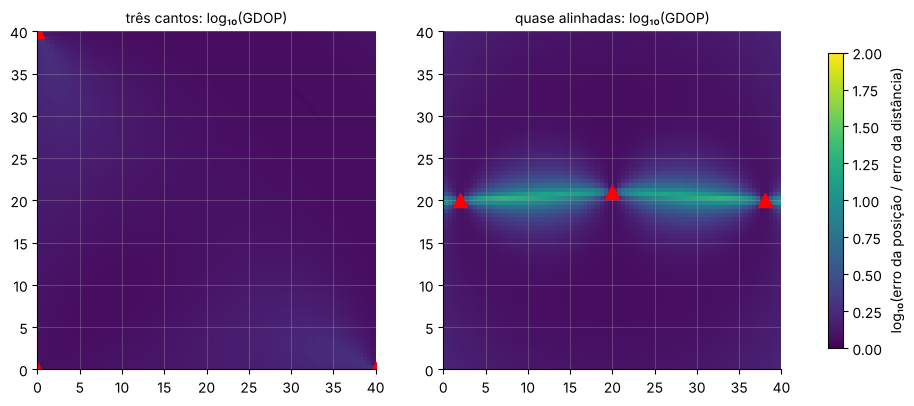


balizas quase alinhadas, alvo em [13. 27.]:
   Gauss–Newton partindo de (13, 27) → [13. 27.]
   Gauss–Newton partindo de (13, 13) → [13.289 14.13 ]  ← um quase reflexo
   resíduo das distâncias no quase reflexo: 0.433 m  (o ruído de cada distância é σ = 0.3 m)
   GDOP no alvo: 1.35;  no quase reflexo: 1.36


In [5]:
def gdop(b, X, Y):
    G = np.full(X.shape, np.nan)
    for i in range(X.shape[0]):
        for j in range(X.shape[1]):
            Jm = jac_dist(np.array([X[i, j], Y[i, j]]), b)
            G[i, j] = np.sqrt(np.trace(np.linalg.inv(Jm.T @ Jm)))
    return G

xs = np.linspace(0.25, 39.75, 80)
X, Y = np.meshgrid(xs, xs)
arranjos = {"três cantos": np.array([[0, 0], [40, 0], [0, 40.0]]),
            "quase alinhadas": np.array([[2, 20], [20, 21], [38, 20.0]])}
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
for a_, (nome, b) in zip(ax, arranjos.items()):
    G = gdop(b, X, Y)
    im = a_.pcolormesh(X, Y, np.log10(G), cmap="viridis", vmin=0, vmax=2, shading="auto")
    a_.plot(*b.T, "r^", ms=10); a_.set_aspect("equal"); a_.set_title(f"{nome}: log₁₀(GDOP)", fontsize=10)
    print(f"{nome:16s} GDOP: mediana {np.median(G):6.2f};  10% piores acima de {np.percentile(G, 90):7.1f};  máximo {G.max():9.1f}")
fig.colorbar(im, ax=ax, shrink=.8, label="log₁₀(erro da posição / erro da distância)")
plt.show()

# o que a GDOP não vê: o quase reflexo
b_al = arranjos["quase alinhadas"]
r_al = distancias(p_ver, b_al)
reflexo = trilat_gn(r_al, b_al, [13.0, 13.0])            # Gauss–Newton partindo do lado de baixo
print(f"\nbalizas quase alinhadas, alvo em {p_ver}:")
print(f"   Gauss–Newton partindo de (13, 27) → {trilat_gn(r_al, b_al, [13.0, 27.0]).round(3)}")
print(f"   Gauss–Newton partindo de (13, 13) → {reflexo.round(3)}  ← um quase reflexo")
res = np.sqrt(np.mean((distancias(reflexo, b_al) - r_al)**2))
print(f"   resíduo das distâncias no quase reflexo: {res:.3f} m  (o ruído de cada distância é σ = {sig_r} m)")
J_r = jac_dist(reflexo, b_al)
print(f"   GDOP no alvo: {np.sqrt(np.trace(np.linalg.inv(jac_dist(p_ver, b_al).T @ jac_dist(p_ver, b_al)))):.2f};  no quase reflexo: {np.sqrt(np.trace(np.linalg.inv(J_r.T @ J_r))):.2f}")

**Leitura.** Com as balizas em três cantos, a GDOP fica entre 1 e 2 em toda a arena: o erro da posição é da ordem do erro de uma distância. Com as balizas quase alinhadas, ela explode numa faixa estreita ao longo da linha das balizas (em cima dela, as distâncias quase não mudam com um deslocamento perpendicular), mas, surpreendentemente, fica boa no resto da arena.

**O que a GDOP não vê.** A GDOP é **local**: mede a precisão em torno de uma solução, supondo que se está perto dela. As balizas quase alinhadas têm um problema **global**: o quase reflexo do alvo do outro lado da linha. Partindo de baixo, Gauss–Newton converge para um ponto perto do reflexo, onde as distâncias diferem das medidas só um pouco mais que o próprio ruído (resíduo de uns 0,4 m, contra $\sigma=0{,}3$ m), e onde a GDOP é tão boa quanto no alvo. Com medidas ruidosas, as duas soluções são quase indistinguíveis, e nenhuma das duas "parece" ruim. O mapa e o resíduo juntos contam a história que cada um sozinho esconde.

> **Nota: o elo com a etapa (d).** Um perseguidor que mede só a distância até o alvo é uma "baliza móvel". Parado, ele define só um círculo; andando, mede distâncias de pontos diferentes, e a geometria dessas medidas, que depende do caminho dele, decide se o alvo é localizável. É a GDOP aplicada ao sensoriamento ativo do notebook I(d).

---

## 4. Mirar um projétil com arrasto

Um lançador está na origem e quer acertar um alvo a $D$ metros, na mesma altura, lançando uma bola com velocidade $v_0$ fixa. A incógnita é o **ângulo** $\theta$. Sem arrasto, a resposta é de escola, $\sin2\theta=gD/v_0^2$, com **duas** soluções, $\theta$ e $90°-\theta$: o tiro direto e o tiro por cima.

Com **arrasto linear** (uma força $-b\mathbf v$ contra a velocidade), as equações do movimento ainda têm solução fechada, que a etapa (c) deduz com o `sympy`. Com $\tau=m/b$:

$$x(t)=v_0\cos\theta\;\tau\,(1-e^{-t/\tau}),\qquad y(t)=-g\tau t+(v_0\sin\theta+g\tau)\,\tau\,(1-e^{-t/\tau}).$$

Acertar o alvo é resolver o sistema de **duas** equações, $x(t)=D$ e $y(t)=0$, nas **duas** incógnitas $(\theta,t)$. Não há fórmula fechada (o tempo aparece dentro e fora da exponencial), e o caminho é Newton em duas variáveis (notebook I(b), seção 4), com o jacobiano calculado pelo `sympy`.

**Os números.** Uma bola de tênis de mesa: $m=2{,}7$ g, raio de 2 cm. A etapa (c) mostra que o arrasto real dela é quadrático, com velocidade terminal de uns 8,4 m/s; aqui, o arrasto linear com a **mesma** velocidade terminal, $g\tau=8{,}38$ m/s, faz o papel de um modelo simplificado, com fórmula fechada. Lançamento a $v_0=8$ m/s, alvo a $D=2{,}5$ m (perto do comprimento da mesa, 2,74 m).

In [6]:
G_GRAV, V_TERM, V0, D_ALVO = 9.81, 8.38, 8.0, 2.5
TAU = V_TERM / G_GRAV
th, t = sp.symbols("theta t", real=True)
xt = V0 * sp.cos(th) * TAU * (1 - sp.exp(-t / TAU))
yt = -G_GRAV * TAU * t + (V0 * sp.sin(th) + G_GRAV * TAU) * TAU * (1 - sp.exp(-t / TAU))
g_sis = sp.Matrix([xt - D_ALVO, yt])
J_sis = g_sis.jacobian([th, t])
print("jacobiano do sistema (θ, t):"); sp.pprint(J_sis.applyfunc(lambda e: sp.simplify(e)))
g_num, J_num = sp.lambdify([th, t], g_sis, "numpy"), sp.lambdify([th, t], J_sis, "numpy")

def newton2(z, n_iter=40, tol=1e-13):
    z = np.array(z, float)
    for i in range(n_iter):
        dz = np.linalg.solve(np.array(J_num(*z), float), -np.array(g_num(*z), float).ravel())
        z = z + dz
        if np.linalg.norm(dz) < tol:
            return z, i + 1
    return z, None

direto, it_d = newton2([0.3, 0.5])
por_cima, it_c = newton2([1.0, 1.0])
for nome, (a_, t_), it in [("tiro direto", direto, it_d), ("tiro por cima", por_cima, it_c)]:
    print(f"{nome:14s}: θ = {np.degrees(a_):6.2f}°, tempo de voo = {t_:.3f} s  ({it} iterações de Newton)")
th_sem = np.degrees(0.5 * np.arcsin(G_GRAV * D_ALVO / V0**2))
print(f"sem arrasto:    θ = {th_sem:6.2f}° ou {90 - th_sem:6.2f}°")
for z in (direto, por_cima):
    confere("  o tiro acerta o alvo", np.array(g_num(*z), float).ravel(), [0, 0], tol=1e-12)
    confere("  scipy.optimize.fsolve concorda", optimize.fsolve(lambda q: np.array(g_num(*q), float).ravel(), z + 0.01,
            fprime=lambda q: np.array(J_num(*q), float), xtol=1e-12), z, tol=1e-10)

jacobiano do sistema (θ, t):


⎡                                             -1.17064439140811⋅t              ↪
⎢-6.83384301732926⋅sin(θ) + 6.83384301732926⋅ℯ                   ⋅sin(θ)       ↪
⎢                                                                              ↪
⎢                                            -1.17064439140811⋅t          ⎛    ↪
⎣6.83384301732926⋅cos(θ) - 6.83384301732926⋅ℯ                   ⋅cos(θ)   ⎝- 8 ↪

↪                     -1.17064439140811⋅t                          ⎤
↪                8.0⋅ℯ                   ⋅cos(θ)                   ⎥
↪                                                                  ⎥
↪      1.17064439140811⋅t                    ⎞  -1.17064439140811⋅t⎥
↪ .38⋅ℯ                   + 8.0⋅sin(θ) + 8.38⎠⋅ℯ                   ⎦
tiro direto   : θ =  15.68°, tempo de voo = 0.408 s  (5 iterações de Newton)
tiro por cima : θ =  60.54°, tempo de voo = 1.164 s  (6 iterações de Newton)
sem arrasto:    θ =  11.27° ou  78.73°
OK     o tiro acerta o alvo:  diferença máxima = 4.44e-1

**Leitura.** O arrasto muda bastante as duas soluções: o tiro direto precisa de um ângulo maior que sem arrasto (a bola perde velocidade horizontal e cai antes), e o tiro por cima precisa de um ângulo **menor** (subir muito é caro quando o ar freia). Newton converge em poucas iterações a partir de chutes razoáveis.

### As bacias de atração

Qual das duas soluções o Newton encontra? Depende do chute inicial. A célula abaixo parte de uma grade de $150\times150$ chutes $(\theta_0,t_0)$ e pinta cada um pela solução a que o Newton chegou. O sistema também tem soluções **sem significado físico** (tempo negativo, ou ângulo acima de 90°, que lança para trás), e o Newton pode encontrá-las, ou não convergir.

tiro direto         :  38.3% dos chutes
tiro por cima       :  39.4% dos chutes
solução não física  :  21.9% dos chutes
não convergiu       :   0.4% dos chutes
algumas soluções não físicas encontradas (θ em graus, t em s): [(-171.0, -0.269), (-90.2, -3.961)]


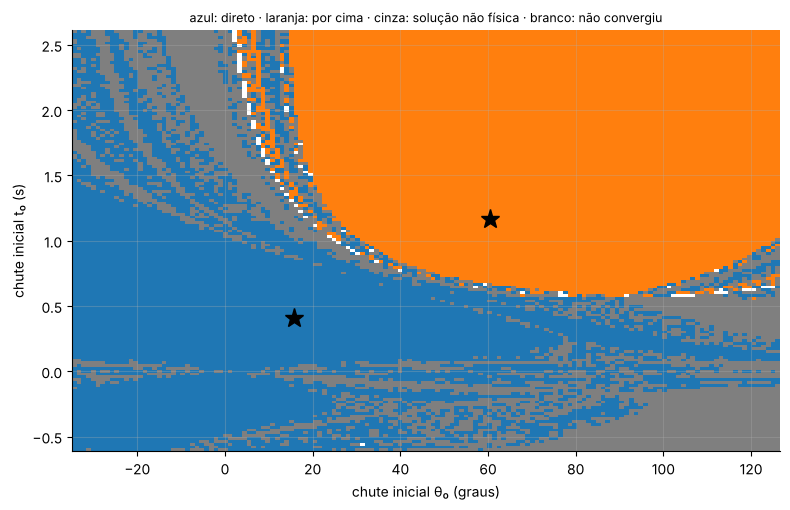

In [7]:
TH0, T0 = np.meshgrid(np.linspace(-0.6, 2.2, 150), np.linspace(-0.6, 2.6, 150))
Z = np.stack([TH0.ravel(), T0.ravel()], 1)
with np.errstate(all="ignore"):
    for _ in range(40):                                   # Newton vetorizado: um sistema 2×2 por chute
        G_ = np.array(g_num(Z[:, 0], Z[:, 1]), float).reshape(2, -1).T
        Jz = np.array([[np.broadcast_to(np.asarray(e, float), Z[:, 0].shape) for e in linha] for linha in J_num(Z[:, 0], Z[:, 1])])
        det = Jz[0, 0] * Jz[1, 1] - Jz[0, 1] * Jz[1, 0]
        d0 = (-G_[:, 0] * Jz[1, 1] + G_[:, 1] * Jz[0, 1]) / det
        d1 = (-G_[:, 1] * Jz[0, 0] + G_[:, 0] * Jz[1, 0]) / det
        Z = Z + np.stack([d0, d1], 1)
    resid = np.linalg.norm(np.array(g_num(Z[:, 0], Z[:, 1]), float).reshape(2, -1).T, axis=1)
Z[:, 0] = np.angle(np.exp(1j * Z[:, 0]))                 # θ e θ + 2πk são o mesmo lançamento
classe = np.full(len(Z), 3)                               # 3: não convergiu
ok = np.isfinite(resid) & (resid < 1e-9)
classe[ok] = 2                                            # 2: solução sem significado físico
classe[ok & (np.linalg.norm(Z - direto, axis=1) < 1e-6)] = 0
classe[ok & (np.linalg.norm(Z - por_cima, axis=1) < 1e-6)] = 1
nomes = ["tiro direto", "tiro por cima", "solução não física", "não convergiu"]
for k, nome in enumerate(nomes):
    print(f"{nome:20s}: {100 * np.mean(classe == k):5.1f}% dos chutes")
outras = Z[(classe == 2)]
if len(outras):
    unicas = np.unique(np.round(outras, 4), axis=0)
    print("algumas soluções não físicas encontradas (θ em graus, t em s):",
          [(round(float(np.degrees(a)), 1), round(float(b), 3)) for a, b in unicas[:6]])

cores = plt.matplotlib.colors.ListedColormap(["tab:blue", "tab:orange", "tab:gray", "white"])
fig, ax = plt.subplots(figsize=(8, 5.2))
ax.pcolormesh(np.degrees(TH0), T0, classe.reshape(TH0.shape), cmap=cores, vmin=-0.5, vmax=3.5, shading="auto")
ax.plot(np.degrees(direto[0]), direto[1], "k*", ms=14); ax.plot(np.degrees(por_cima[0]), por_cima[1], "k*", ms=14)
ax.set_xlabel("chute inicial θ₀ (graus)"); ax.set_ylabel("chute inicial t₀ (s)")
ax.set_title("azul: direto · laranja: por cima · cinza: solução não física · branco: não convergiu", fontsize=9)
plt.tight_layout(); plt.show()

**Leitura.** Antes de classificar, o ângulo foi reduzido a $(-180°,180°]$, porque $\theta$ e $\theta+360°$ são o mesmo lançamento: o Newton, que não sabe disso, às vezes "encontra" a mesma solução com dezenas de voltas a mais. A figura é a imagem de um fato que a série vai encontrar de novo: **um problema não linear com várias soluções divide o espaço dos chutes em bacias**, e as fronteiras entre bacias podem ser complicadas. Chutes perto de uma solução convergem para ela; chutes com tempo de voo negativo ou muito pequeno caem com frequência em soluções sem significado físico. Num programa de verdade, restringe-se o chute ao que faz sentido (ângulo entre 0 e 90°, tempo positivo) e confere-se a solução encontrada.

A escolha entre o tiro direto e o tiro por cima não é matemática: é do lançador. No filtro de Kalman, a escolha entre duas hipóteses também não é do Newton: é das medidas e do modelo. Quando o filtro iterado da etapa (d) converge para a solução "errada", ele está fazendo exatamente o que o Newton desta figura faz.

---

## 5. Exercícios

1. **Triangulação com três observadores.** Acrescente um terceiro observador à seção 1 e resolva o sistema $3\times2$ por mínimos quadrados. O erro melhora mais acrescentando um observador ou afastando os dois que já existem?
2. **O reflexo.** Na seção 3, ponha as quatro balizas sobre a reta $y=20$. Rode Gauss–Newton partindo de $(13,13)$ e de $(13,27)$. O que acontece, e por quê? O que diz a GDOP nesse caso?
3. **Pesos.** O sistema linearizado da seção 3 pode ser melhorado com mínimos quadrados **ponderados**. Mostre que o erro de $r_i^2$ tem desvio aproximado $2r_i\sigma$ e use pesos $1/r_i^2$. Quanto o erro se aproxima da cota?
4. **Alcance máximo.** No modelo de arrasto linear da seção 4, encontre o ângulo que maximiza o alcance para $v_0=8$ m/s resolvendo $\mathrm d D/\mathrm d\theta=0$ com Newton (o `sympy` dá a derivada). Compare com 45°.
5. **Fora de alcance.** Aumente $D$ até o sistema da seção 4 deixar de ter solução. Como o Newton se comporta perto desse limite? Relacione com o jacobiano ficando singular (as duas soluções se fundem numa só).